# **Домашнее задание № 1**

Ковалев Кирилл Александрович

Курс "Методы машинного обучения".

# **Выбор датасета**

В работе испольузется датасет `covertype` из сборника [inria-soda/tabular-benchmark](https://huggingface.co/datasets/polinaeterna/tabular-benchmark), с помощью которого возможно предсказывать принадлежность территории к одной из двух категорий лесного покрова.

Выбор указанного датасета среди остальных из сборника обоснован наличием числовых и бинарных признаков и постановкой задачи типа "Классификация", что подходит для используемых в ходе работы моделей моделей.

In [1]:
%pip install -q datasets scikit-learn pandas matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

In [3]:
dataset = load_dataset(
    "polinaeterna/tabular-benchmark",
    name="clf_cat_covertype",
    split="train"
)

df = dataset.to_pandas()

# **Анализ данных**

In [4]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes.value_counts())

Размер датасета: (423680, 55)

Типы данных:
int64      49
float64     6
Name: count, dtype: int64


In [5]:
print("Информация о признаках:")
df.info()

Информация о признаках:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 423680 entries, 0 to 423679
Data columns (total 55 columns):
 #   Column                              Non-Null Count   Dtype  
---  ------                              --------------   -----  
 0   Elevation                           423680 non-null  float64
 1   Aspect                              423680 non-null  float64
 2   Slope                               423680 non-null  int64  
 3   Horizontal_Distance_To_Hydrology    423680 non-null  float64
 4   Vertical_Distance_To_Hydrology      423680 non-null  float64
 5   Horizontal_Distance_To_Roadways     423680 non-null  float64
 6   Hillshade_9am                       423680 non-null  int64  
 7   Hillshade_Noon                      423680 non-null  int64  
 8   Hillshade_3pm                       423680 non-null  int64  
 9   Horizontal_Distance_To_Fire_Points  423680 non-null  float64
 10  Wilderness_Area1                    423680 non-null  int64  
 11  Wi

In [6]:
print("Статистика:")
print(df.describe().T)

Статистика:
                                       count         mean          std  \
Elevation                           423680.0  3024.767025   201.615937   
Aspect                              423680.0   154.075965   112.265872   
Slope                               423680.0    13.332215     6.972801   
Horizontal_Distance_To_Hydrology    423680.0   275.084248   213.439101   
Vertical_Distance_To_Hydrology      423680.0    43.995844    57.038281   
Horizontal_Distance_To_Roadways     423680.0  2521.057036  1562.523298   
Hillshade_9am                       423680.0   212.931014    24.889943   
Hillshade_Noon                      423680.0   224.374799    18.366811   
Hillshade_3pm                       423680.0   143.415351    36.141922   
Horizontal_Distance_To_Fire_Points  423680.0  2087.911811  1334.918363   
Wilderness_Area1                    423680.0     0.507643     0.499942   
Wilderness_Area2                    423680.0     0.059705     0.236941   
Wilderness_Area3          

In [7]:
missing = df.isnull().sum()

print("Пропущенные значения:")
print(missing[missing > 0])

print("\nКоличество дубликатов:", df.duplicated().sum())

print("\nКоличество уникальных значений:")
print(df.nunique().sort_values())

Пропущенные значения:
Series([], dtype: int64)

Количество дубликатов: 0

Количество уникальных значений:
Soil_Type1                               1
Soil_Type15                              1
Soil_Type14                              1
Soil_Type5                               1
Soil_Type37                              1
Wilderness_Area2                         2
Soil_Type2                               2
Wilderness_Area1                         2
Soil_Type6                               2
Soil_Type4                               2
Soil_Type8                               2
Soil_Type7                               2
Soil_Type3                               2
Wilderness_Area4                         2
Soil_Type9                               2
Wilderness_Area3                         2
Soil_Type13                              2
Soil_Type16                              2
Soil_Type12                              2
Soil_Type11                              2
Soil_Type17                       

In [8]:
constant_features = [
    col for col in df.columns
    if df[col].nunique() <= 1 and col != "class"
]

print("Постоянные признаки:", constant_features)

print("\nРаспределение классов:")
print(df["class"].value_counts())

print("\nДоли классов:")
print(df["class"].value_counts(normalize=True))

Постоянные признаки: ['Soil_Type1', 'Soil_Type5', 'Soil_Type14', 'Soil_Type15', 'Soil_Type37']

Распределение классов:
class
1    211840
2    211840
Name: count, dtype: int64

Доли классов:
class
1    0.5
2    0.5
Name: proportion, dtype: float64


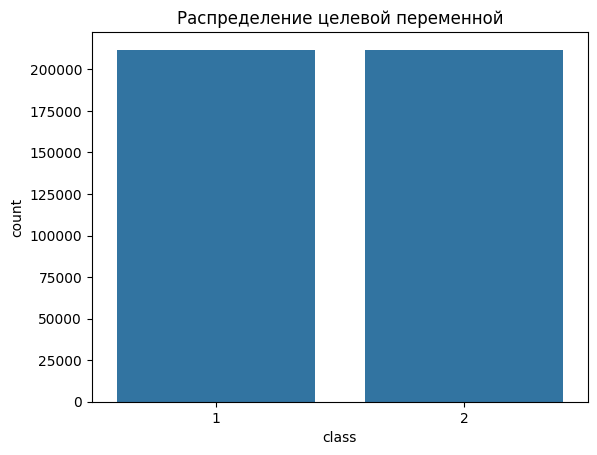

In [9]:
sns.countplot(data=df, x="class")
plt.title("Распределение целевой переменной")
plt.show()


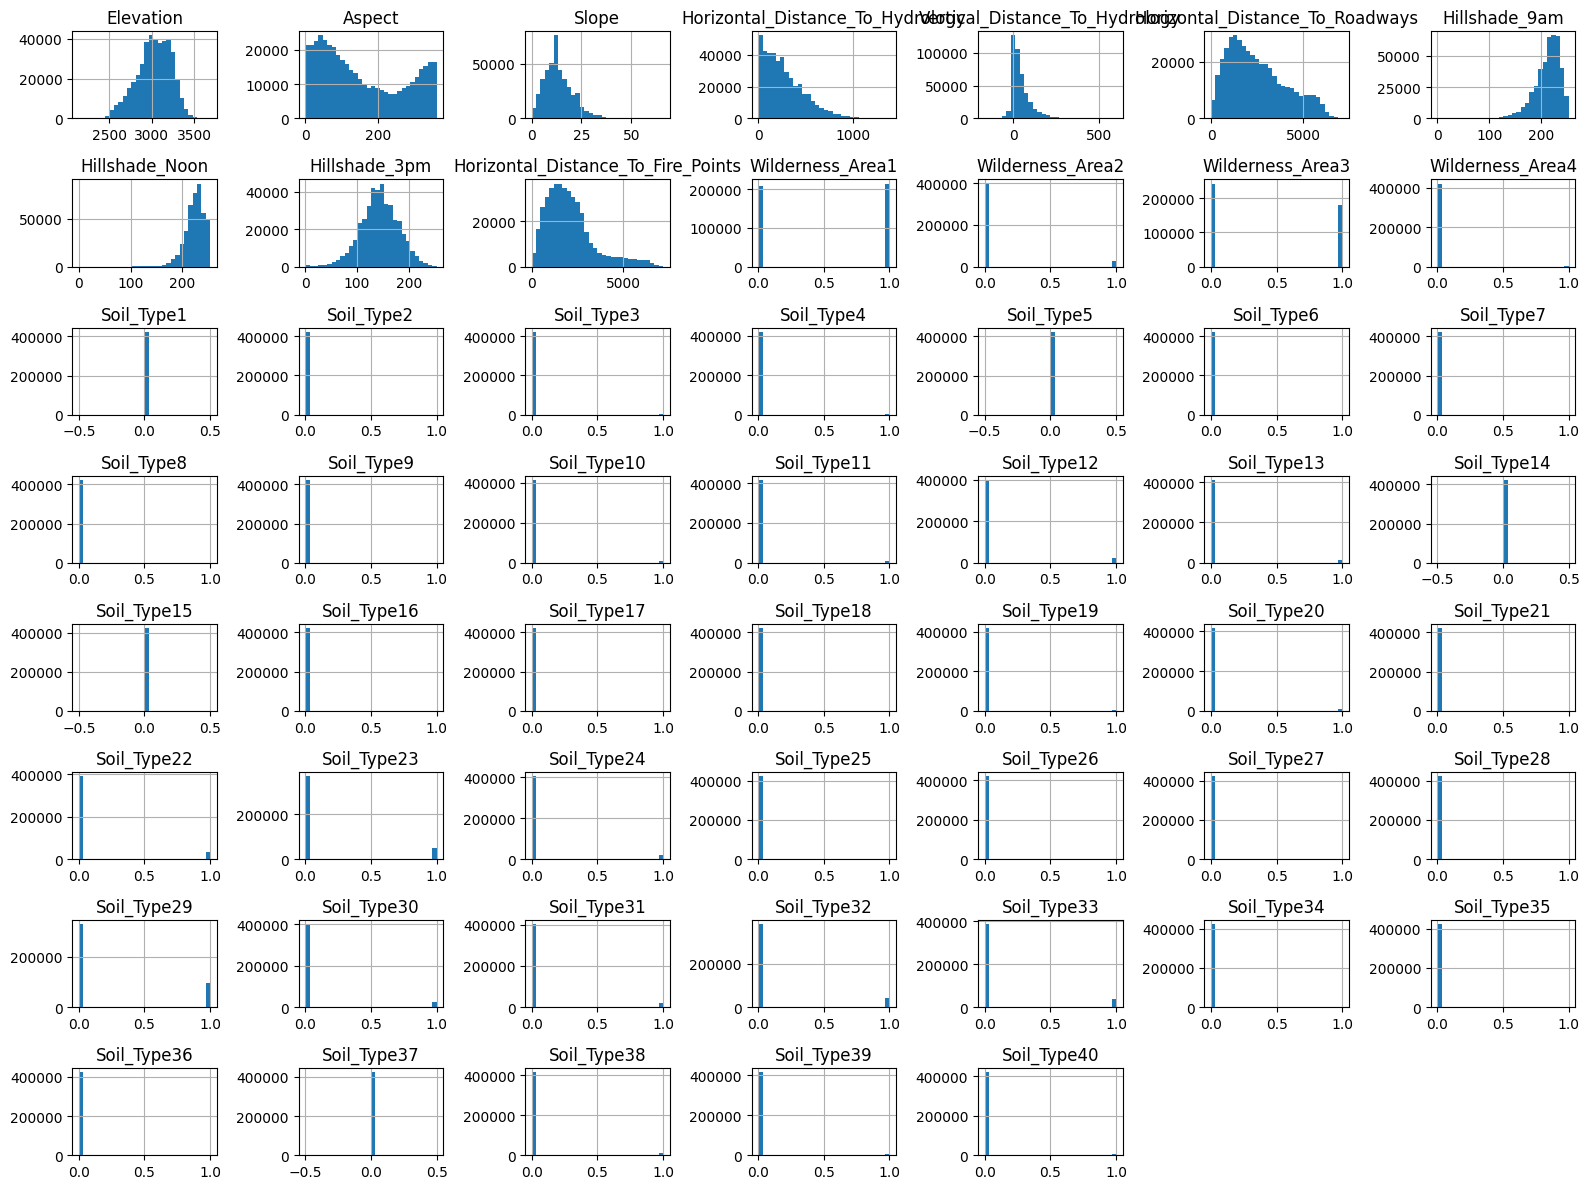

In [10]:
numeric_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.drop("class")

df[numeric_features].hist(
    figsize=(16, 12),
    bins=30
)
plt.tight_layout()
plt.title("Распределение числовых признаков")
plt.show()

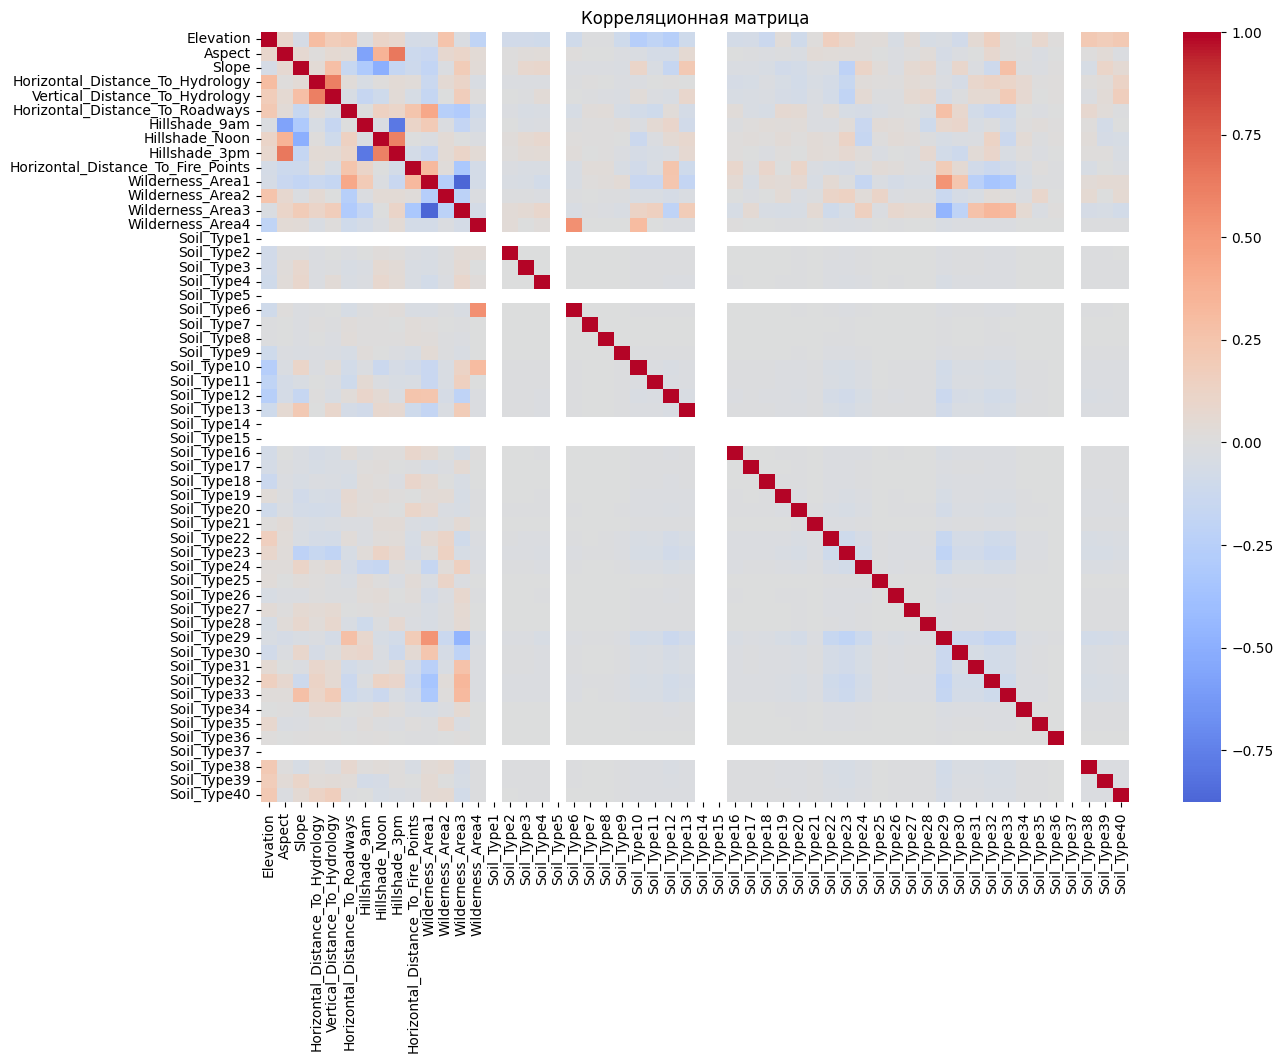

In [11]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df[numeric_features].corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Корреляционная матрица")
plt.show()

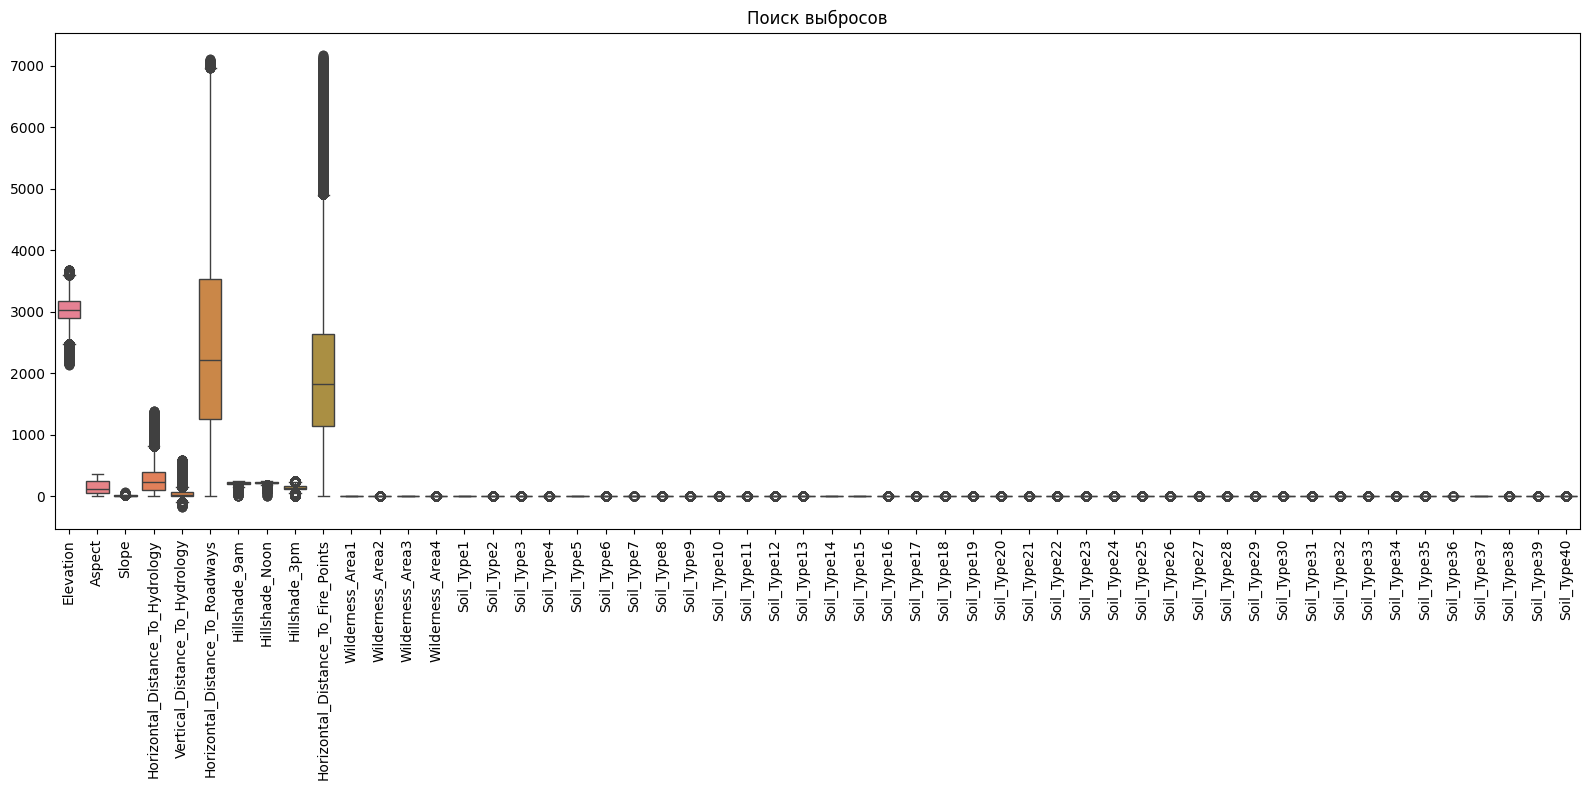

In [12]:
plt.figure(figsize=(16, 8))

sns.boxplot(
    data=df[numeric_features]
)

plt.xticks(rotation=90)
plt.title("Поиск выбросов")
plt.tight_layout()
plt.show()

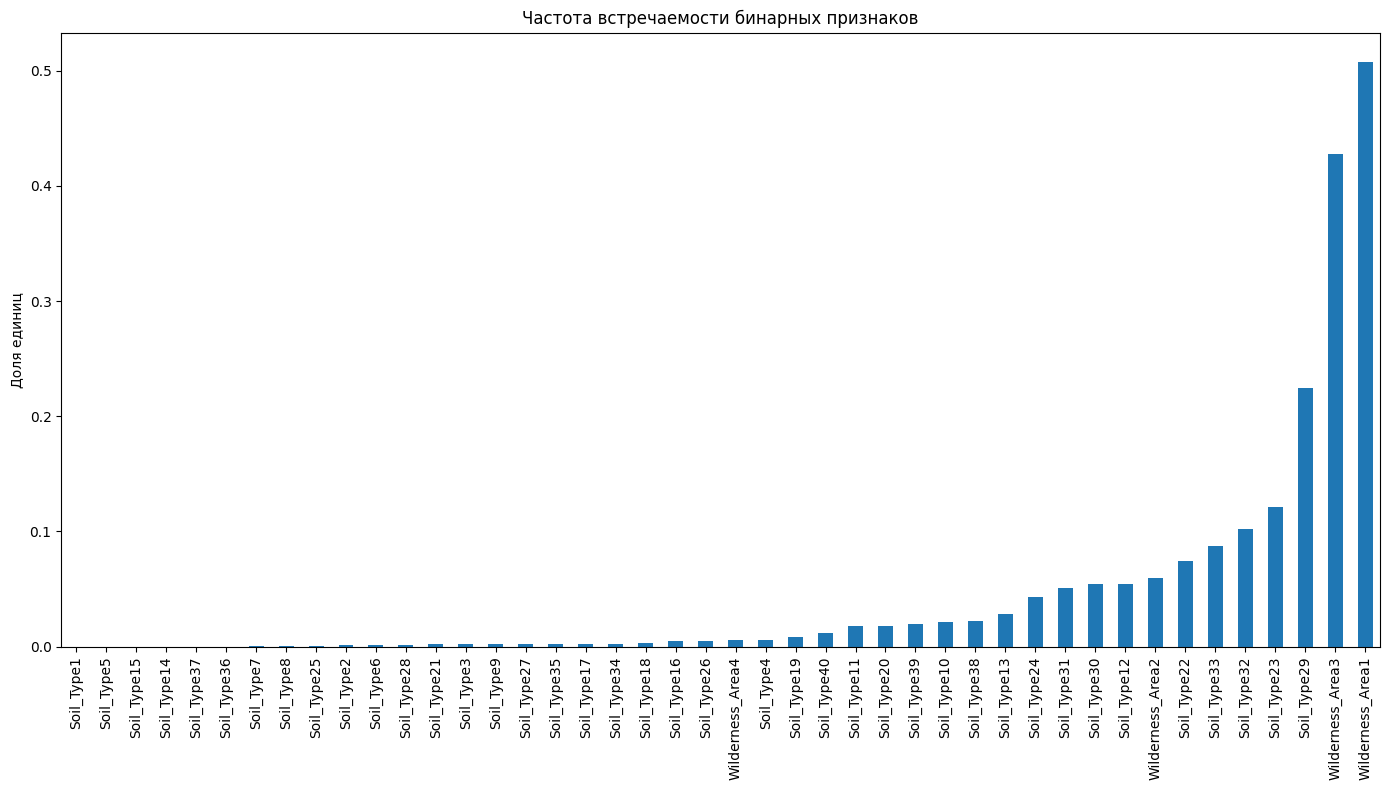

In [13]:
binary_features = [
    col for col in df.columns
    if col.startswith("Wilderness_Area")
    or col.startswith("Soil_Type")
]

binary_frequency = df[binary_features].mean().sort_values()

plt.figure(figsize=(14, 8))

binary_frequency.plot(kind="bar")
plt.title("Частота встречаемости бинарных признаков")
plt.ylabel("Доля единиц")
plt.tight_layout()
plt.show()


По результатам EDA получены следующие наблюдения:

1. Датасет содержит 423 680 строк и 54 исходных признака (без учёта целевой переменной — 53 признака).
2. Пропущенных значений и полных дубликатов не обнаружено. Поэтому удалять строки или массово заполнять пропуски не требуется.
3. Целевые классы сбалансированы: по 211 840 наблюдений (50%) на каждый класс. Использование SMOTE, oversampling или undersampling не требуется.
4. Найдено пять константных признаков: Soil_Type1, Soil_Type5, Soil_Type14, Soil_Type15, Soil_Type37. Они не различают наблюдения и не могут помочь классификатору.
5. Числовые признаки имеют разные масштабы: например, Slope принимает значения от 0 до 66, Elevation — от 2142 до 3686, а расстояния до объектов могут превышать 7000. Для логистической регрессии это важно, поскольку оптимизация и регуляризация чувствительны к масштабу признаков.
6. Aspect - циклическая величина в градусах. Значения около 0° и 360° соответствуют близким направлениям, хотя в исходном числовом представлении находятся на противоположных концах диапазона.
7. Признаки Wilderness_Area* и Soil_Type* уже закодированы бинарными индикаторами 0/1. Повторное применение One-Hot Encoding не требуется.



# **Применённые преобразования**

1. Столбец Aspect заменён двумя признаками:
\[
Aspect_{sin}=\sin(Aspect\cdot\pi/180),\qquad
Aspect_{cos}=\cos(Aspect\cdot\pi/180).
\]
Так сохраняется круговая геометрия направления: близкие углы около 0°/360° получают близкие координаты на единичной окружности. Это особенно полезно для логистической регрессии, которой сложнее самостоятельно представить циклическую зависимость одной линейной переменной.

2. Удаление константных признаков через VarianceThreshold(threshold=0).
Селектор обучается только на X_train, после чего то же преобразование применяется к X_test. Это предотвращает утечку информации из тестовой выборки при определении набора признаков. Удаляются признаки с нулевой дисперсией; остальные бинарные признаки сохраняются.

3. Числовые признаки обрабатываются отдельно от уже закодированных индикаторов Wilderness_Area* и Soil_Type*. Категориальные индикаторы не нужно масштабировать или повторно кодировать.

4. Для числовой ветви применяется StandardScaler:
\[
z=\frac{x-\mu}{\sigma}.
\]
Это помогает логистической регрессии сходиться и делает регуляризацию более сопоставимой между признаками с разными единицами измерения. Для Random Forest стандартизация не является необходимой: деревья выбирают пороговые разбиения и в общем случае инвариантны к монотонному масштабированию признаков.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

X = df.drop(columns=["class"]).copy()
y = df["class"]

In [15]:
X["Aspect_sin"] = np.sin(np.deg2rad(X["Aspect"]))
X["Aspect_cos"] = np.cos(np.deg2rad(X["Aspect"]))
X = X.drop(columns=["Aspect"])

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
X_train.shape, X_test.shape

((338944, 55), (84736, 55))

In [17]:
selector = VarianceThreshold(threshold=0)

X_train = pd.DataFrame(
    selector.fit_transform(X_train),
    columns=X_train.columns[selector.get_support()],
    index=X_train.index
)

X_test = pd.DataFrame(
    selector.transform(X_test),
    columns=X_train.columns,
    index=X_test.index
)

In [18]:
binary_features = [
    col for col in X_train.columns
    if col.startswith("Wilderness_Area")
    or col.startswith("Soil_Type")
]

numeric_features = [
    col for col in X_train.columns
    if col not in binary_features
]

# **Обучение**

In [21]:
preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "binary",
        SimpleImputer(strategy="most_frequent"),
        binary_features
    )
])

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        C=1.0,
        random_state=42,
    ))
])

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42,
    ))
])

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model
}

In [23]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions[name]),
        "Precision": precision_score(
            y_test, predictions[name], pos_label=2
        ),
        "Recall": recall_score(
            y_test, predictions[name], pos_label=2
        ),
        "F1": f1_score(
            y_test, predictions[name], pos_label=2
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities[name]
        )
    })

    print(f"\n{name}")
    print(classification_report(y_test, predictions[name]))

results_df = pd.DataFrame(results)
print(results_df)


Logistic Regression
              precision    recall  f1-score   support

           1       0.78      0.77      0.77     42368
           2       0.77      0.78      0.78     42368

    accuracy                           0.77     84736
   macro avg       0.77      0.77      0.77     84736
weighted avg       0.77      0.77      0.77     84736


Random Forest
              precision    recall  f1-score   support

           1       0.95      0.96      0.96     42368
           2       0.96      0.95      0.96     42368

    accuracy                           0.96     84736
   macro avg       0.96      0.96      0.96     84736
weighted avg       0.96      0.96      0.96     84736

                 Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Logistic Regression  0.774311   0.770569  0.781226  0.775861  0.848670
1        Random Forest  0.955780   0.963248  0.947720  0.955421  0.992608


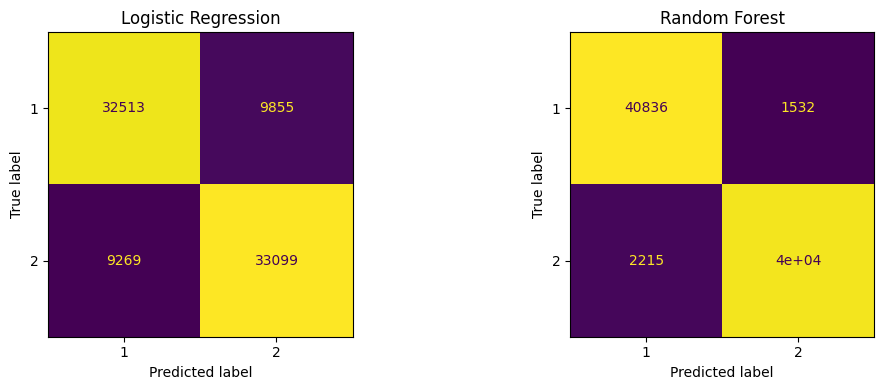

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [29]:
print(max([tree.get_depth() for tree in forest_model.named_steps["classifier"].estimators_]))

59


# **Эксперименты**

**Сила регуляризации C для логистической регрессии**

In [31]:
results = []
predictions = {}
probabilities = {}
c_values = [0.01, 0.1, 1, 10]

for c in c_values:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
          max_iter=2000,
          C=c,
          random_state=42,
        ))
    ])

    model.fit(X_train, y_train)

    predictions[c] = model.predict(X_test)
    probabilities[c] = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": f"C = {c}",
        "Accuracy": accuracy_score(y_test, predictions[c]),
        "Precision": precision_score(
            y_test, predictions[c], pos_label=2
        ),
        "Recall": recall_score(
            y_test, predictions[c], pos_label=2
        ),
        "F1": f1_score(
            y_test, predictions[c], pos_label=2
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities[c]
        )
    })

    print(f"\nC = {c}")
    print(classification_report(y_test, predictions[c]))

results_df = pd.DataFrame(results)
print(results_df)



C = 0.01
              precision    recall  f1-score   support

           1       0.78      0.77      0.77     42368
           2       0.77      0.78      0.78     42368

    accuracy                           0.77     84736
   macro avg       0.77      0.77      0.77     84736
weighted avg       0.77      0.77      0.77     84736


C = 0.1
              precision    recall  f1-score   support

           1       0.78      0.77      0.77     42368
           2       0.77      0.78      0.78     42368

    accuracy                           0.77     84736
   macro avg       0.77      0.77      0.77     84736
weighted avg       0.77      0.77      0.77     84736


C = 1
              precision    recall  f1-score   support

           1       0.78      0.77      0.77     42368
           2       0.77      0.78      0.78     42368

    accuracy                           0.77     84736
   macro avg       0.77      0.77      0.77     84736
weighted avg       0.77      0.77      0.77     

Изменения крайне малы: разница Accuracy между худшим и лучшим вариантом составляет около 0,03 процентного пункта, а F1 практически не меняется. Следовательно, в проверенном диапазоне сила регуляризации не является главным ограничением качества логистической регрессии. Даже ослабление регуляризации не позволяет линейной модели приблизиться к Random Forest.

**Семплинг max_depth для RandomForestClassifier**

In [32]:
results = []
predictions = {}
probabilities = {}
max_depth_values = [5, 10, 20, 40]

for max_depth in max_depth_values:
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=max_depth,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=42,
        ))
    ])

    model.fit(X_train, y_train)

    predictions[max_depth] = model.predict(X_test)
    probabilities[max_depth] = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": f"Max depth = {max_depth}",
        "Accuracy": accuracy_score(y_test, predictions[max_depth]),
        "Precision": precision_score(
            y_test, predictions[max_depth], pos_label=2
        ),
        "Recall": recall_score(
            y_test, predictions[max_depth], pos_label=2
        ),
        "F1": f1_score(
            y_test, predictions[max_depth], pos_label=2
        ),
        "ROC-AUC": roc_auc_score(
            y_test, probabilities[max_depth]
        )
    })

    print(f"\nMax depth = {max_depth}")
    print(classification_report(y_test, predictions[max_depth]))

results_df = pd.DataFrame(results)
print(results_df)



Max depth = 5
              precision    recall  f1-score   support

           1       0.77      0.74      0.76     42368
           2       0.75      0.78      0.77     42368

    accuracy                           0.76     84736
   macro avg       0.76      0.76      0.76     84736
weighted avg       0.76      0.76      0.76     84736


Max depth = 10
              precision    recall  f1-score   support

           1       0.79      0.80      0.80     42368
           2       0.80      0.79      0.80     42368

    accuracy                           0.80     84736
   macro avg       0.80      0.80      0.80     84736
weighted avg       0.80      0.80      0.80     84736


Max depth = 20
              precision    recall  f1-score   support

           1       0.90      0.92      0.91     42368
           2       0.92      0.90      0.91     42368

    accuracy                           0.91     84736
   macro avg       0.91      0.91      0.91     84736
weighted avg       0.91    

Заметно как при повышении максимальной глубины дерева растёт качество модели. В базовой модели max_depth=None; фактическая максимальная глубина одного из деревьев составила 59.

Однако нельзя заключать, что дальнейшее увеличение глубины обязательно улучшит качество: оно может повысить риск переобучения и затраты вычислений.

**Удаление признака Aspect**

In [35]:
dropped = ["Aspect_sin", "Aspect_cos"]
numeric_reduced = [c for c in numeric_features if c not in dropped]

preprocessor_reduced = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_reduced
    ),
    (
        "binary",
        SimpleImputer(strategy="most_frequent"),
        binary_features
    )
])

forest_reduced = Pipeline([
    ("preprocessor", preprocessor_reduced),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=None,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42,
    ))
])

forest_reduced.fit(X_train.drop(columns=dropped), y_train)

predictions = forest_reduced.predict(X_test.drop(columns=dropped))
probabilities = forest_reduced.predict_proba(X_test.drop(columns=dropped))[:, 1]

results_df = pd.DataFrame([{
    "Model": "Forest Reduced",
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(
        y_test, predictions, pos_label=2
    ),
    "Recall": recall_score(
        y_test, predictions, pos_label=2
    ),
    "F1": f1_score(
        y_test, predictions, pos_label=2
    ),
    "ROC-AUC": roc_auc_score(
        y_test, probabilities
    )
}])
print(results_df)

            Model  Accuracy  Precision    Recall        F1  ROC-AUC
0  Forest Reduced  0.960395   0.967456  0.952842  0.960093  0.99405


Удаление признаков улучшило Accuracy примерно на 0,46 процентного пункта и F1 примерно на 0,47 процентного пункта. Следовательно, в данном эксперименте циклическое кодирование Aspect не помогло Random Forest, а исключение полученных признаков дало небольшой прирост.

Это не означает, что Aspect бесполезен: вывод относится к конкретной модели, параметрам и разбиению данных. Для логистической регрессии циклическое кодирование может оставаться полезным, поскольку линейная модель иначе не учитывает близость углов около 0° и 360°.

**Cross validation**

In [36]:
from sklearn.model_selection import cross_val_score

cv_scores = pd.DataFrame({
    name: cross_val_score(model, X_train, y_train, cv=5, scoring="f1_macro")
    for name, model in models.items()
})
cv_scores.round(3)

,Logistic Regression,Random Forest
0,0.774,0.951
1,0.774,0.952
2,0.770,0.950
3,0.771,0.950
4,0.774,0.952


In [37]:
cv_scores.agg(["mean", "std"]).round(3)

,Logistic Regression,Random Forest
mean,0.773,0.951
std,0.002,0.001


Random Forest сохраняет преимущество во всех пяти фолдах. Средний F1 macro леса выше примерно на 0,178 (17,8 процентного пункта), а малое стандартное отклонение у обеих моделей говорит о том, что результат мало меняется между случайными фолдами данного разбиения. Это подтверждает, что преимущество леса не является особенностью только одной тестовой выборки.

# **Выводы**

- Лучшая модель для выбранного датасета — Random Forest. На тестовой выборке базовый лес получил Accuracy 0.9558, F1 класса 2 0.9554 и ROC-AUC 0.9926 против 0.7743, 0.7759 и 0.8487 у логистической регрессии. По 5-fold кросс-валидации средний F1 macro составил 0.951 против 0.773.

- Логистическая регрессия путает классы в обоих направлениях примерно одинаково. Random Forest ошибается существенно реже и несколько чаще относит истинный класс 2 к классу 1.